<a href="https://colab.research.google.com/github/ericalh04/DATA602TermProject/blob/main/DATA602_Term_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **DATA602 Term Project**

Group Members: Kristin Dan & Erica Honadel

## **Data Cleaning & Processing**

Data relating to migration and population estimates were dowloaded from the CDC and Census Bureau datasets. These were cleaned and processed in Excel and uploaded to our Google Drive.

We will first begin by mounting our Google Drive to Colab, so that we can access the CDC data files saved to a Drive folder.

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


Please note that in these datasets, Estimated Population (2000-2025) includes the year 2025. This will be important for our ML portion of the project.

The model for open population growth is:

Change in Population = Birth - Death + Immigration - Emigration

We can simplify this model as: Change in Population = Natural Growth + Migratory Growth

First, we need to quantify Natural Growth and Migratory Growth between each year for each county. We will do this using a percent change.

In [ ]:
import pandas as pd

estimated_population_df = pd.read_excel('/content/drive/MyDrive/DATA602_ProjectData/clean_data/us_county_estpop_2000_2025.xlsx')
netmigration_df = pd.read_csv('/content/drive/MyDrive/DATA602_ProjectData/clean_data/us_county_net_migration_2000_2024.csv')

# check for unique entires in both estimated population and net migration
estimated_population_df.nunique()

,0
FIPS,3143
County,1878
State,55
2000_estpop,3090
2001_estpop,3080
2002_estpop,3076
2003_estpop,3082
2004_estpop,3087
2005_estpop,3068
2006_estpop,3078


We need to calculate the population change for each county from year to year. This is saved as us_county_population_change_2000_2025.csv

In [ ]:
import numpy as np

estpop = estimated_population_df.copy()


pop_change = pd.DataFrame({
    "FIPS": estpop["FIPS"],
    "County": estpop["County"],
    "State": estpop["State"],
    "2000_estpop": pd.to_numeric(
        estpop["2000_estpop"], errors="coerce"
    )
})

for year in range(2001, 2025):

    current_col = f"{year}_estpop"
    previous_col = f"{year - 1}_estpop"
    change_col = f"{year}_population_change"

    current_population = pd.to_numeric(estpop[current_col], errors="coerce")

    previous_population = pd.to_numeric(estpop[previous_col], errors="coerce")

    # Annual change = current population - previous population
    pop_change[change_col] = (current_population - previous_population)

pop_change.to_csv("us_county_population_change_2000_2024.csv", index=False)

The CDC does not report number of birth for counties with a population less than 100,000. About 2000 out of 3500 counties will have missing data. So we can estimate Natural Growth by rearranging the Change in Population equation;

Natural Growth = Change in Population - Migration Growth.

Natural growth will be saved as us_county_natural_growth_2000_2024.csv

Please note that 2000 is listed as the estimated population as a baseline.

In [ ]:
estpop = estimated_population_df.copy()
netmig = netmigration_df.copy()

# Standardize FIPS codes
for df in [estpop, netmig]:
    df["FIPS"] = (df["FIPS"].astype("string")
        .str.replace(r"\.0$", "", regex=True).str.strip().str.zfill(5))


# match by FIPS code
merged = estpop.merge(
    netmig,
    on="FIPS",
    how="inner",
    suffixes=("_estpop", "_netmig"),
    validate="one_to_one"
)

# Use county and state names from the population dataset
new_col = pd.DataFrame({
    "FIPS": merged["FIPS"],
    "County": merged["County_estpop"],
    "State": merged["State_estpop"],
    "2000_estpop": pd.to_numeric(
        merged["2000_estpop"], errors="coerce"
    )
})

# Calculating Natural Growth
for year in range(2001, 2025):

    current_col = f"{year}_estpop"
    previous_col = f"{year - 1}_estpop"
    migration_col = f"{year}_netmig"
    natural_col = f"{year}_natural_growth"

    # Ensure values are numeric
    current_population = pd.to_numeric(merged[current_col], errors="coerce")

    previous_population = pd.to_numeric(merged[previous_col], errors="coerce")

    migration_growth = pd.to_numeric(merged[migration_col], errors="coerce")

    # Population change from previous year
    population_change = (current_population - previous_population)

    # Natural growth = population change - net migration
    new_col[natural_col] = (population_change - migration_growth)

new_col.to_csv("us_county_natural_growth_2000_2024.csv", index=False)

Some FIPS codes are missing or duplicated. This is due to redistricting or combining of borders. I will check for missing values and manually correct these errors.

In [ ]:
estimated_population_df = pd.read_excel('/content/drive/MyDrive/DATA602_ProjectData/clean_data/us_county_estpop_2000_2025.xlsx')
netmigration_df = pd.read_csv('/content/drive/MyDrive/DATA602_ProjectData/clean_data/us_county_net_migration_2000_2024.csv')
naturalchange_df = pd.read_csv('/content/drive/MyDrive/DATA602_ProjectData/clean_data/us_county_natural_growth_2000_2024.csv')

# change which dataframe to check
df = naturalchange_df

print(df.isna().sum())

FIPS                    0
County                  0
State                   0
2000_estpop             0
2001_natural_growth     0
2002_natural_growth     0
2003_natural_growth     0
2004_natural_growth     0
2005_natural_growth     0
2006_natural_growth     0
2007_natural_growth     0
2008_natural_growth     0
2009_natural_growth     0
2010_natural_growth     3
2011_natural_growth     3
2012_natural_growth     3
2013_natural_growth     3
2014_natural_growth     3
2015_natural_growth     3
2016_natural_growth     3
2017_natural_growth     3
2018_natural_growth     3
2019_natural_growth     3
2020_natural_growth    11
2021_natural_growth    11
2022_natural_growth    11
2023_natural_growth    11
2024_natural_growth    11
dtype: int64


Based on this result, we can proceed. FIPS codes 9001, 9003, 9005, 9007, 9009, 9011, 9013, 9015 are missing data due to a consolidation for CT. 2261 was abolished and split into 2063 and 2066. 2270 was abolished. 51515 had its designation changed, meaning that exists on certain vintages but not new data collections. We can still use the data that is not missing in the hypothesis testing. This concludes the data preprocessing for the non-ML portion of the project.

For the ML portion of the project, we have two different data sources. One is data is downloaded from the CDC and another is data accessed from the Census Bureau through their API. (Add sources later)

We will now save each individual file into its own data frame. The file paths may need to be changed depending on where the files have been saved.

In [ ]:
import pandas as pd

growth_df = pd.read_csv('/content/drive/MyDrive/DATA602_ProjectData/clean_data/us_county_growth_long_2001_2024.csv')

In [ ]:
growth_df.nunique()

,0
FIPS,3143
County,1878
State,55
Year,24
Natural_Growth,6303
Net_Migration,8015


There are 55 unique states, but only 50 actual state plus DC. Therefore, we know that this data is still messy.

In [ ]:
for index, row in growth_df.iterrows():
  if row['State'] == 'Alaska':
    growth_df.iloc[index, 2] = 'AK'
  elif row['State'] == 'Virginia':
    growth_df.iloc[index, 2] = 'VA'
  elif row['State'] == 'South Dakota':
    growth_df.iloc[index, 2] = 'SD'
  elif row['State'] == 'Louisiana':
    growth_df.iloc[index, 2] = 'LA'

There are also some counties with missing data due to things such as low population and redistricting. We will simply remove all such counties.

In [ ]:
to_remove = []

for index, row in growth_df.iterrows():
  if pd.isna(row['Natural_Growth']) or pd.isna(row['Net_Migration']):
    to_remove.append(row['FIPS'])

for fips in to_remove:
  growth_df = growth_df.drop(growth_df[growth_df['FIPS'] == fips].index)

We will now access the Census Bureau data through their API.

In the Census Bureau's American Community Survey (ACS) data, each feature has a unique label, which can be see here:

https://api.census.gov/data/2023/acs/acs1/profile/groups/DP05.html

We will create a dictionary of relevant mappings to readable English Labels.

In [ ]:
ACS_feature_mapping_dic_old = {
  'DP05_0001E': 'Total Population',
  'DP05_0002E': 'Total Population Male',
  'DP05_0003E': 'Total Population Female',
  'DP05_0004E': 'Population Under 5',
  'DP05_0016E': 'Population 85 and Over',
  'DP05_0017E': 'Median Population Age',
  'DP05_0018E': 'Population 18 Years and Over',
  'DP05_0020E': 'Population 62 and Over'
}

ACS_features_old = "DP05_0001E,DP05_0002E,DP05_0003E,DP05_0004E,DP05_0016E,DP05_0017E,DP05_0018E,DP05_0020E"

ACS_feature_mapping_dic_new = {
  'DP05_0001E': 'Total Population',
  'DP05_0002E': 'Total Population Male',
  'DP05_0003E': 'Total Population Female',
  'DP05_0005E': 'Population Under 5',
  'DP05_0017E': 'Population 85 and Over',
  'DP05_0018E': 'Median Population Age',
  'DP05_0019E': 'Population Under 18',
  'DP05_0023E': 'Population 62 and Over'
}

ACS_features_new = "DP05_0001E,DP05_0002E,DP05_0003E,DP05_0005E,DP05_0017E,DP05_0018E,DP05_0019E,DP05_0023E"

In [ ]:
import requests

acs_df = pd.DataFrame()

params_old = {
    'get': ACS_features_old,
    'for': 'county:*',
    'key': '70ffe620e63dee1bb58a2cd3409561739629e369'

}

params_new = {
    'get': ACS_features_new,
    'for': 'county:*',
    'key': '70ffe620e63dee1bb58a2cd3409561739629e369'
}

for year in range(2012, 2017):
  acs_api_url = f'https://api.census.gov/data/{year}/acs/acs5/profile'
  r = requests.get(acs_api_url, params_old)
  data = r.json()
  temp_df = pd.DataFrame(data[1:], columns=data[0])
  temp_df['Year'] = year
  temp_df['Population Under 18'] = pd.to_numeric(temp_df['DP05_0001E']) - pd.to_numeric(temp_df['DP05_0018E'])
  temp_df = temp_df.rename(columns=ACS_feature_mapping_dic_old)
  acs_df = pd.concat([acs_df, temp_df])

for year in range(2017, 2025):
  acs_api_url = f'https://api.census.gov/data/{year}/acs/acs5/profile'
  r = requests.get(acs_api_url, params_new)
  data = r.json()
  temp_df = pd.DataFrame(data[1:], columns=data[0])
  temp_df['Year'] = year
  temp_df = temp_df.rename(columns=ACS_feature_mapping_dic_new)
  acs_df = pd.concat([acs_df, temp_df])

acs_df

,Total Population,Total Population Male,Total Population Female,Population Under 5,Population 85 and Over,Median Population Age,Population 18 Years and Over,Population 62 and Over,state,county,Year,Population Under 18
0,12668,6059,6609,789,434,43.0,9593,2914,29,115,2012,3075
1,40330,19477,20853,2731,939,39.6,30326,8316,29,091,2012,10004
2,52964,26826,26138,3509,580,29.7,40984,7039,29,101,2012,11980
3,35507,17526,17981,2317,722,39.1,26659,6754,29,105,2012,8848
4,9140,4568,4572,562,215,43.1,7002,1948,29,125,2012,2138
...,...,...,...,...,...,...,...,...,...,...,...,...
3217,53892,25663,28229,1833,1833,44.7,NaN,14693,72,145,2024,8712
3218,8078,4207,3871,276,133,46.5,NaN,2236,72,147,2024,1363
3219,21556,10335,11221,842,584,44.0,NaN,5722,72,149,2024,3938
3220,29400,14095,15305,854,873,47.4,NaN,8718,72,151,2024,4530


We will now reorder the columns, create a new column for the FIPS, and sort by FIPS.

In [ ]:
acs_df['FIPS'] = acs_df['state'].astype(str) + acs_df['county'].astype(str)
acs_df = acs_df.drop(columns=['state', 'county', 'Population 18 Years and Over'])
acs_df = acs_df[['FIPS', 'Year', 'Total Population', 'Total Population Male', 'Total Population Female', 'Population Under 5', 'Population Under 18', 'Population 62 and Over', 'Population 85 and Over', 'Median Population Age']]
acs_df = acs_df.sort_values(by=['FIPS', 'Year'])
acs_df = acs_df.reset_index()
acs_df = acs_df.drop(columns=['index'])
acs_df

,FIPS,Year,Total Population,Total Population Male,Total Population Female,Population Under 5,Population Under 18,Population 62 and Over,Population 85 and Over,Median Population Age
0,01001,2012,54590,26538,28052,3529,14637,8253,660,37.0
1,01001,2013,54907,26793,28114,3489,14392,8442,696,37.5
2,01001,2014,55136,26774,28362,3415,14214,8969,669,37.9
3,01001,2015,55221,26745,28476,3242,14044,9007,607,37.7
4,01001,2016,55049,26877,28172,3172,13853,9225,659,37.8
...,...,...,...,...,...,...,...,...,...,...
41865,72153,2020,34501,16484,18017,1307,6286,8995,686,45.1
41866,72153,2021,34704,16548,18156,1226,6149,9298,609,45.5
41867,72153,2022,33988,16176,17812,1118,5767,9567,584,46.2
41868,72153,2023,33509,15920,17589,1046,5474,9791,571,46.7


We will be repeating the same process as above but with the Census Bureau's ACM subject data.

In [ ]:
ACS_subject_feature_mapping_dic = {
    'S1901_C01_012E': 'Median Household Income',
    'S1701_C03_001E': 'Percentage of Population Below Poverty Level',
    'S1501_C02_014E': 'Percentage of Adults 25 and Older with High School Diploma or Higher'
}

ACS_subject_features = "S1901_C01_012E,S1701_C03_001E,S1501_C02_014E"

acs_subject_df = pd.DataFrame()

params = {
    'get': ACS_subject_features,
    'for': 'county:*',
    'key': '70ffe620e63dee1bb58a2cd3409561739629e369'

}

for year in range(2012, 2025):
  acs_api_url = f'https://api.census.gov/data/{year}/acs/acs5/subject'
  r = requests.get(acs_api_url, params)
  data = r.json()
  temp2_df = pd.DataFrame(data[1:], columns=data[0])
  temp2_df['Year'] = year
  temp2_df = temp2_df.rename(columns=ACS_subject_feature_mapping_dic)
  acs_subject_df = pd.concat([acs_subject_df, temp2_df])

acs_subject_df['FIPS'] = acs_subject_df['state'].astype(str) + acs_subject_df['county'].astype(str)
acs_subject_df = acs_subject_df.drop(columns=['state', 'county'])
acs_subject_df = acs_subject_df[['FIPS', 'Year', 'Median Household Income', 'Percentage of Population Below Poverty Level', 'Percentage of Adults 25 and Older with High School Diploma or Higher']]
acs_subject_df = acs_subject_df.sort_values(by=['FIPS', 'Year'])
acs_subject_df = acs_subject_df.reset_index()
acs_subject_df = acs_subject_df.drop(columns=['index'])
acs_subject_df

,FIPS,Year,Median Household Income,Percentage of Population Below Poverty Level,Percentage of Adults 25 and Older with High School Diploma or Higher
0,01001,2012,53773,11.6,85.0
1,01001,2013,53682,12.1,84.8
2,01001,2014,52475,12.8,85.6
3,01001,2015,51281,12.9,87.2
4,01001,2016,53099,12.3,87.6
...,...,...,...,...,...
41865,72153,2020,14813,48.9,75.8
41866,72153,2021,16444,46.4,77.8
41867,72153,2022,19827,43.7,79.0
41868,72153,2023,21918,44.6,79.5


In [ ]:
ACS2_feature_mapping_dic = {
  'B05002_002E': 'Population Native Born',
  'B05002_013E': 'Population Foreign Born'
}

ACS2_features = "B05002_002E,B05002_013E"

acs2_df = pd.DataFrame()

params = {
    'get': ACS2_features,
    'for': 'county:*',
    'key': '70ffe620e63dee1bb58a2cd3409561739629e369'

}

for year in range(2012, 2025):
  acs_api_url = f'https://api.census.gov/data/{year}/acs/acs5'
  r = requests.get(acs_api_url, params)
  data = r.json()
  temp3_df = pd.DataFrame(data[1:], columns=data[0])
  temp3_df['Year'] = year
  temp3_df = temp3_df.rename(columns=ACS2_feature_mapping_dic)
  acs2_df = pd.concat([acs2_df, temp3_df])

acs2_df['FIPS'] = acs2_df['state'].astype(str) + acs2_df['county'].astype(str)
acs2_df = acs2_df.drop(columns=['state', 'county'])
acs2_df = acs2_df[['FIPS', 'Year', 'Population Native Born', 'Population Foreign Born']]
acs2_df = acs2_df.sort_values(by=['FIPS', 'Year'])
acs2_df = acs2_df.reset_index()
acs2_df = acs2_df.drop(columns=['index'])
acs2_df

,FIPS,Year,Population Native Born,Population Foreign Born
0,01001,2012,53834,756
1,01001,2013,54019,888
2,01001,2014,54364,772
3,01001,2015,54360,861
4,01001,2016,54037,1012
...,...,...,...,...
41865,72153,2020,34343,158
41866,72153,2021,34541,163
41867,72153,2022,33858,130
41868,72153,2023,33344,165


We will now merge all three of the ACS DataFrames into one large DataFrame.

In [ ]:
final_acs_df = acs_df.merge(acs_subject_df, on=['FIPS', 'Year'], how="inner")
final_acs_df = final_acs_df.merge(acs2_df, on=['FIPS', 'Year'], how="inner")
final_acs_df

We will also turn some of the total population columns into percentages, so that we can compare between counties with different population sizes.

In [ ]:
final_acs_df['Percentage Population Male'] = pd.to_numeric(final_acs_df['Total Population Male'])/pd.to_numeric(final_acs_df['Total Population'])
final_acs_df['Percentage Population Female'] = pd.to_numeric(final_acs_df['Total Population Female'])/pd.to_numeric(final_acs_df['Total Population'])
final_acs_df['Percentage Population Under 5'] = pd.to_numeric(final_acs_df['Population Under 5'])/pd.to_numeric(final_acs_df['Total Population'])
final_acs_df['Percentage Population Under 18'] = pd.to_numeric(final_acs_df['Population Under 18'])/pd.to_numeric(final_acs_df['Total Population'])
final_acs_df['Percentage Population 62 and Over'] = pd.to_numeric(final_acs_df['Population 62 and Over'])/pd.to_numeric(final_acs_df['Total Population'])
final_acs_df['Percentage Population 85 and Over'] = pd.to_numeric(final_acs_df['Population 85 and Over'])/pd.to_numeric(final_acs_df['Total Population'])
final_acs_df['Percentage Population Native Born'] = pd.to_numeric(final_acs_df['Population Native Born'])/pd.to_numeric(final_acs_df['Total Population'])
final_acs_df['Percentage Population Foreign Born'] = pd.to_numeric(final_acs_df['Population Foreign Born'])/pd.to_numeric(final_acs_df['Total Population'])
final_acs_df['Percentage of Population Below Poverty Level'] = pd.to_numeric(final_acs_df['Percentage of Population Below Poverty Level'])/100
final_acs_df['Percentage of Adults 25 and Older with High School Diploma or Higher'] = pd.to_numeric(final_acs_df['Percentage of Adults 25 and Older with High School Diploma or Higher'])/100
final_acs_df = final_acs_df.drop(columns=['Total Population Male', 'Total Population Female', 'Population Under 5', 'Population Under 18', 'Population 62 and Over', 'Population 85 and Over', 'Population Native Born', 'Population Foreign Born'])
final_acs_df

NameError: name 'pd' is not defined

We will be saving this data as a csv just in case for future reference.

In [ ]:
final_acs_df.to_csv('ACS Data 2012 to 2024.csv')

# **Descriptive Statistics**

In [ ]:
growth_df['Delta'] = growth_df['Natural_Growth'] - growth_df['Net_Migration']
growth_df = growth_df.dropna(subset='Delta')
growth_df[['Natural_Growth', 'Net_Migration', 'Delta']].describe()

,Natural_Growth,Net_Migration,Delta
count,75144.000000,75144.000000,75144.000000
mean,453.079447,313.240738,139.838710
std,2353.318673,3267.318389,4007.318845
min,-20472.000000,-248105.000000,-99826.000000
25%,-33.000000,-92.000000,-152.000000
50%,23.000000,5.000000,12.000000
75%,191.000000,205.000000,176.000000
max,85434.000000,110477.000000,232088.000000


Note: Outliers were excluded in the following visualization, as the inclusion of them lead to the box portion of the boxplot to be extremely small and uninterpretable, due to the large number of positive and negative outliers. The exclusion of these points do not take away from our ability to analyze the shape of the distribution.

Text(0.5, 1.0, 'Distribution of Natural Growth and Net Migration')

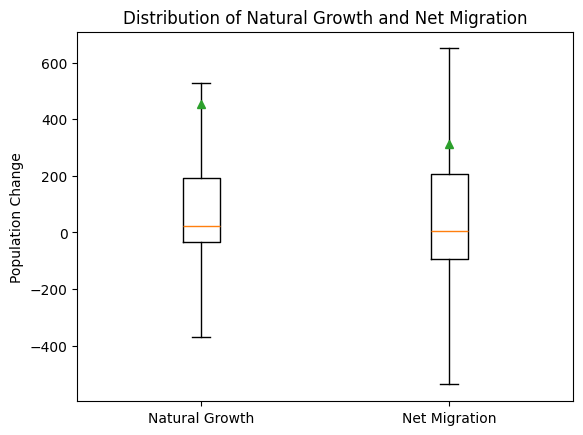

In [ ]:
import matplotlib.pyplot as plt

plt.boxplot([growth_df['Natural_Growth'], growth_df['Net_Migration']], showfliers=False, showmeans=True, tick_labels=['Natural Growth', 'Net Migration'])
plt.ylabel('Population Change')
plt.title('Distribution of Natural Growth and Net Migration')

**Conclusion #1:** On average, natural growth is greater than net migration. The standard deviation is greater for net migration than natural growth, indicating more variability.

The box plots show that for both natural growth and net migration, the mean is greater than median, suggesting that the data is right skewed. This is more apparent in natural growth compared to net migration. Just as natural growth, the IQR is greater for net migration than natural growth.

# **Hypothesis Testing**

Does natural population growth contribute more to year-to-year population change than net migration?

Let 𝚫 = Natural Change - Net Migration.

Null hypothesis: On average, natural growth does not contribute to year-to-year population change more than net migration.
𝚫  ≤ 0

Alternate Hypothesis:  On average, natural growth contributes to year-to-year population change more than net migration.
𝚫  > 0


In [ ]:
from scipy.stats import ttest_1samp

grouped_growth = growth_df.groupby('FIPS')
results = pd.DataFrame()
results[['FIPS', 'Average Delta', 't-statistic', 'p-value']] = None

for fips, group in grouped_growth:
  t_stat, p_val = ttest_1samp(group['Delta'].dropna(), popmean = 0, alternative='greater')
  temp = {
      'FIPS': fips,
      'Average Delta': group['Delta'].mean(),
      't-statistic': t_stat,
      'p-value': p_val
  }
  results = pd.concat([results, pd.DataFrame(temp, index=[0])])
  results = results.reset_index(drop=True)

results

/tmp/ipykernel_3846/345191328.py:15: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  results = pd.concat([results, pd.DataFrame(temp, index=[0])])


,FIPS,Average Delta,t-statistic,p-value
0,1001,75.208333,0.977173,0.169325
1,1003,-3671.000000,-7.445544,1.000000
2,1005,152.375000,3.351686,0.001382
3,1007,13.583333,0.279217,0.391287
4,1009,-264.250000,-3.077379,0.997337
...,...,...,...,...
3126,56037,575.750000,5.375336,0.000009
3127,56039,130.333333,3.573787,0.000805
3128,56041,266.708333,5.857707,0.000003
3129,56043,62.875000,2.922194,0.003833


Note: A p-value near 1, such as counties 1003 and 1009, does not necessarily, mean that there is no difference between natural change and net migration. It suggests that the average delta is very negative, meaning that net migration is greater than natural growth. However, given that this is a right-tailed t-test, it also does not statistically show that net migration is greater than natural growth.

In [ ]:
results['Decision'] = None

for index, row in results.iterrows():
  if row['p-value'] < 0.05:
    results.iloc[index, 4] = 'Reject Null'
  else:
    results.iloc[index, 4] = 'Fail to Reject Null'

results

,FIPS,Average Delta,t-statistic,p-value,Decision
0,1001,75.208333,0.977173,0.169325,Fail to Reject Null
1,1003,-3671.000000,-7.445544,1.000000,Fail to Reject Null
2,1005,152.375000,3.351686,0.001382,Reject Null
3,1007,13.583333,0.279217,0.391287,Fail to Reject Null
4,1009,-264.250000,-3.077379,0.997337,Fail to Reject Null
...,...,...,...,...,...
3126,56037,575.750000,5.375336,0.000009,Reject Null
3127,56039,130.333333,3.573787,0.000805,Reject Null
3128,56041,266.708333,5.857707,0.000003,Reject Null
3129,56043,62.875000,2.922194,0.003833,Reject Null


In [ ]:
results['Decision'].value_counts()

,count
Decision,
Fail to Reject Null,1971
Reject Null,1160


In [ ]:
results = results.merge(growth_df[['FIPS', 'State']].drop_duplicates(subset='FIPS'), on='FIPS', how='left')
proportions_dic = {}
grouped = results.groupby(by='State')
for state, group in grouped:
  print(state)
  proportion = (group['Decision'] == 'Reject Null').mean()
  proportions_dic[state] = proportion
  display(group.reset_index())
  display(group['Decision'].value_counts())
  print('\n')

AK


,index,FIPS,Average Delta,t-statistic,p-value,Decision,State
0,67,2013,24.291667,1.075048,1.467510e-01,Fail to Reject Null,AK
1,68,2016,90.208333,2.295812,1.556825e-02,Reject Null,AK
2,69,2020,4514.041667,8.324544,1.076762e-08,Reject Null,AK
3,70,2050,473.958333,16.532672,1.465156e-14,Reject Null,AK
4,71,2060,33.208333,4.435645,9.502894e-05,Reject Null,AK
5,72,2068,-4.250000,-0.341779,6.321898e-01,Fail to Reject Null,AK
6,73,2070,104.458333,8.748890,4.467232e-09,Reject Null,AK
7,74,2090,1974.708333,7.422515,7.566145e-08,Reject Null,AK
8,75,2100,-9.375000,-1.048969,8.474548e-01,Fail to Reject Null,AK
9,76,2105,37.916667,4.478119,8.547539e-05,Reject Null,AK


,count
Decision,
Reject Null,20
Fail to Reject Null,7




AL


,index,FIPS,Average Delta,t-statistic,p-value,Decision,State
0,0,1001,75.208333,0.977173,0.169325,Fail to Reject Null,AL
1,1,1003,-3671.000000,-7.445544,1.000000,Fail to Reject Null,AL
2,2,1005,152.375000,3.351686,0.001382,Reject Null,AL
3,3,1007,13.583333,0.279217,0.391287,Fail to Reject Null,AL
4,4,1009,-264.250000,-3.077379,0.997337,Fail to Reject Null,AL
...,...,...,...,...,...,...,...
62,62,1125,517.500000,1.107687,0.139724,Fail to Reject Null,AL
63,63,1127,-154.875000,-1.830902,0.959949,Fail to Reject Null,AL
64,64,1129,83.375000,2.770399,0.005442,Reject Null,AL
65,65,1131,92.375000,4.005294,0.000278,Reject Null,AL


...

,index,FIPS,Average Delta,t-statistic,p-value,Decision,State
0,2981,54001,-74.166667,-3.014116,0.996909,Fail to Reject Null,WV
1,2982,54003,-1455.791667,-5.636185,0.999995,Fail to Reject Null,WV
2,2983,54005,121.375000,3.463257,0.001054,Reject Null,WV
3,2984,54007,-87.208333,-5.445630,0.999992,Fail to Reject Null,WV
4,2985,54009,0.833333,0.030525,0.487956,Fail to Reject Null,WV
5,2986,54011,176.750000,1.638441,0.057470,Fail to Reject Null,WV
6,2987,54013,-9.708333,-0.597451,0.721978,Fail to Reject Null,WV
7,2988,54015,-6.875000,-0.416627,0.659593,Fail to Reject Null,WV
8,2989,54017,-14.750000,-0.537670,0.702015,Fail to Reject Null,WV
9,2990,54019,-90.625000,-2.435439,0.988481,Fail to Reject Null,WV


,count
Decision,
Fail to Reject Null,46
Reject Null,9




WY


,index,FIPS,Average Delta,t-statistic,p-value,Decision,State
0,3108,56001,97.125000,1.327179,0.098737,Fail to Reject Null,WY
1,3109,56003,-45.750000,-1.863844,0.962420,Fail to Reject Null,WY
2,3110,56005,412.541667,2.266904,0.016555,Reject Null,WY
3,3111,56007,147.083333,3.773058,0.000493,Reject Null,WY
4,3112,56009,40.708333,1.140171,0.132975,Fail to Reject Null,WY
5,3113,56011,-27.375000,-1.595169,0.937838,Fail to Reject Null,WY
6,3114,56013,141.250000,2.019116,0.027639,Reject Null,WY
7,3115,56015,-7.500000,-0.270859,0.605542,Fail to Reject Null,WY
8,3116,56017,-4.708333,-0.370704,0.642875,Fail to Reject Null,WY
9,3117,56019,-75.291667,-3.935588,0.999670,Fail to Reject Null,WY


,count
Decision,
Fail to Reject Null,15
Reject Null,8


In [ ]:
sorted(proportions_dic.items(), key=lambda item: item[1], reverse=True)

[('AK', np.float64(0.7407407407407407)),
 ('NY', np.float64(0.6935483870967742)),
 ('IA', np.float64(0.6464646464646465)),
 ('LA', np.float64(0.640625)),
 ('NM', np.float64(0.6363636363636364)),
 ('KS', np.float64(0.6190476190476191)),
 ('NJ', np.float64(0.6190476190476191)),
 ('NE', np.float64(0.6129032258064516)),
 ('HI', np.float64(0.6)),
 ('SD', np.float64(0.6)),
 ('CA', np.float64(0.5862068965517241)),
 ('MN', np.float64(0.5517241379310345)),
 ('IL', np.float64(0.5490196078431373)),
 ('ND', np.float64(0.5471698113207547)),
 ('OH', np.float64(0.5340909090909091)),
 ('UT', np.float64(0.5172413793103449)),
 ('MS', np.float64(0.5121951219512195)),
 ('MA', np.float64(0.5)),
 ('IN', np.float64(0.4891304347826087)),
 ('AL', np.float64(0.40298507462686567)),
 ('AR', np.float64(0.4)),
 ('RI', np.float64(0.4)),
 ('WI', np.float64(0.375)),
 ('ID', np.float64(0.36363636363636365)),
 ('WY', np.float64(0.34782608695652173)),
 ('TX', np.float64(0.3346456692913386)),
 ('DE', np.float64(0.33333333

**Conclusion #2:** 62.95% of counties failed to reject the null hypothesis, which indicates that natural growth does contribute to year-to-year poulation change.

There does not appear to be any regional patterns as to which states had a higher proportion of counties that rejected the null hypothesis.



Below, is a heatmap to show regional trends of migratory or natrual growth between the years 2000 and 2024.

First, we need to combine us_county_net_migration_2000_2024.csv and us_county_natural_growth_2000_2024.csv into one datasheet

# **PAIRED T-TEST**

0        False
1        False
2        False
3        False
4        False
         ...  
75427    False
75428    False
75429    False
75430    False
75431    False
Length: 75432, dtype: bool


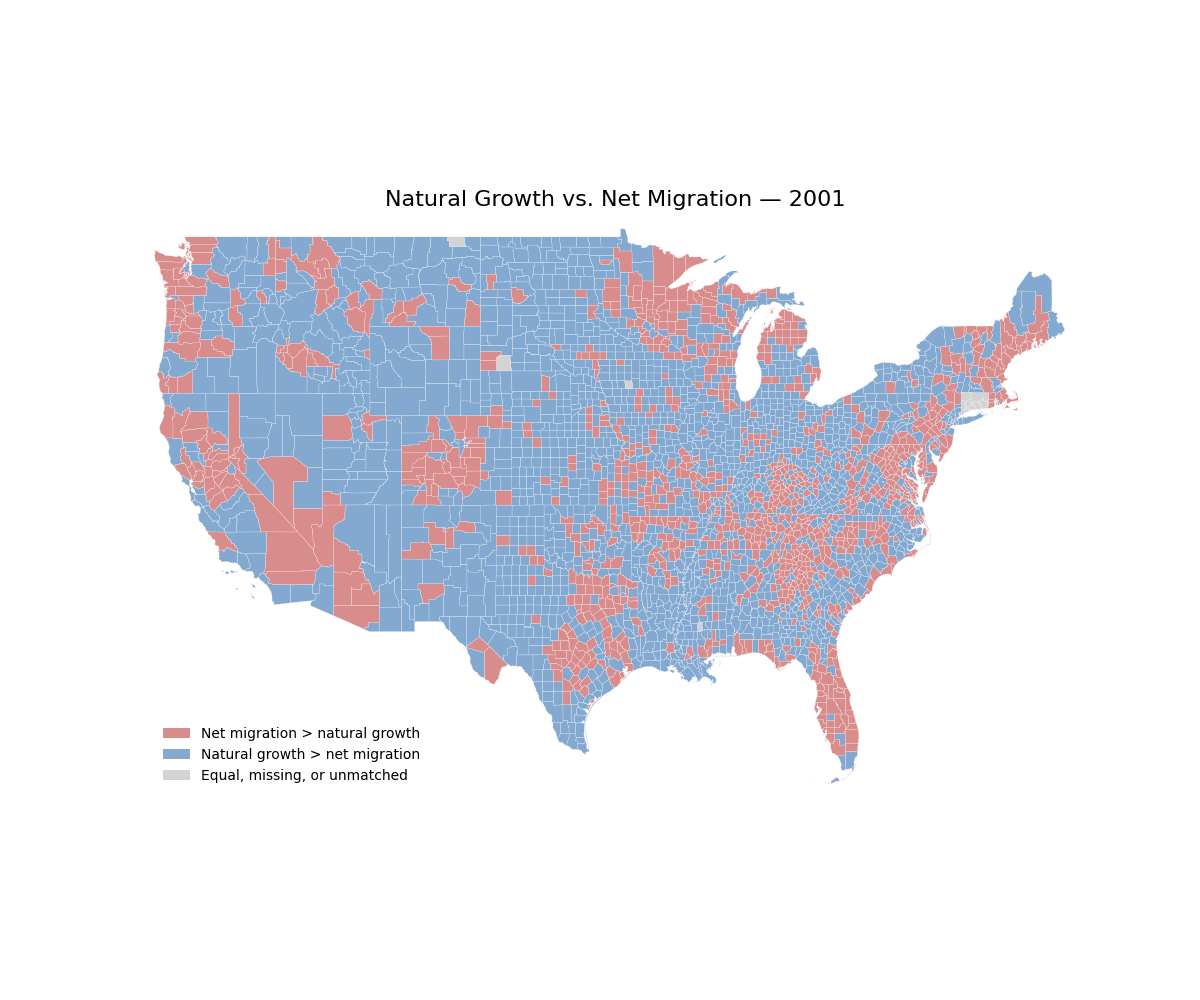

In [ ]:

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

heatmap_df = pd.read_csv('/content/drive/MyDrive/DATA602_ProjectData/clean_data/us_county_growth_long_2001_2024.csv')

# Standardize FIPS codes
heatmap_df["FIPS"] = (heatmap_df["FIPS"].astype("string")
    .str.replace(r"\.0$", "", regex=True).str.strip().str.zfill(5))

# assign RED (1) if net migration is greather than natural growth
# assign BLUE (2) if natural growth is greater than net migration
# assign GRAY (0) if equal or missing data, or county is unmatched
heatmap_df["Color"]  = 0
ok = heatmap_df["Net_Migration"].notna() & heatmap_df["Natural_Growth"].notna()

heatmap_df.loc[ok & (heatmap_df["Net_Migration"] > heatmap_df["Natural_Growth"]),"Color"] = 1
heatmap_df.loc[ok & (heatmap_df["Net_Migration"] < heatmap_df["Natural_Growth"]),"Color"] = 2

# boundaries from U.S. Census County boundaries
counties = gpd.read_file("https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_county_5m.zip")
counties["FIPS"] = counties["GEOID"].astype("string").str.strip().str.zfill(5)
counties = counties[~counties["STATEFP"].isin(["72", "60", "66", "69", "78"])].copy()

# Figure
years = sorted(heatmap_df["Year"].dropna().unique())
duplicates = heatmap_df.duplicated(["FIPS", "Year"], keep=False)
print(duplicates)

colormap = ListedColormap(["lightgray", "#D98C8C", "#83A9D1"])

from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

fig, ax = plt.subplots(figsize=(12, 10))

def update(year):
    ax.clear()

    year_by_year = heatmap_df.loc[heatmap_df["Year"] == year, ["FIPS", "Color"]]

    heat_map = counties.merge(year_by_year, on = "FIPS", how = "left", validate = "one_to_one")

    heat_map["Color"] = (heat_map["Color"].fillna(0).astype(int))

    ax.set_title(f"Natural Growth vs. Net Migration — {year}", fontsize=16)

    heat_map.plot(column = "Color", ax = ax, cmap = colormap,
        vmin = 0, vmax = 2, linewidth = 0.15, edgecolor = "white")

    legend_colors = [
        Patch(facecolor = "#D98C8C", label = "Net migration > natural growth"),
        Patch(facecolor = "#83A9D1", label = "Natural growth > net migration"),
        Patch(facecolor = "lightgray", label = "Equal, missing, or unmatched")
    ]

    ax.set_xlim(-125, -66)
    ax.set_ylim(24, 50)
    ax.legend(handles = legend_colors, loc = "lower left", fontsize = 10, frameon = False)
    ax.set_axis_off()

# animation
animation = FuncAnimation(fig, update, frames = years, interval = 1000, repeat = True)
animation.save("/content/drive/MyDrive/DATA602_ProjectData/clean_data/HeatMap.gif", writer = PillowWriter(fps = 1))

plt.close(fig)
display(Image(filename = "/content/drive/MyDrive/DATA602_ProjectData/clean_data/HeatMap.gif"))


Visually, over the years net migration becomes greater than natural growth. The supports the Hypothesis testing that Net Migration is Larger then Natural growth.

This next visual will compare by year, the number of counties whose natural growth is larger than net migration.

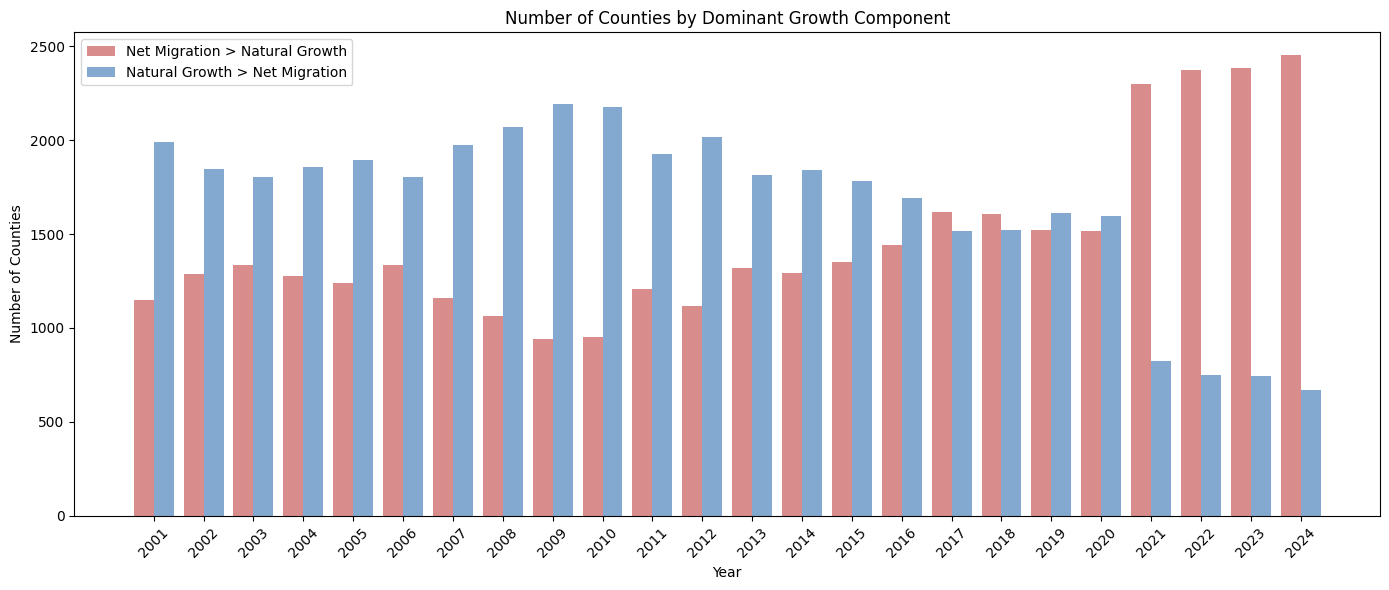

In [ ]:
barchart_df = pd.read_csv('/content/drive/MyDrive/DATA602_ProjectData/clean_data/us_county_growth_long_2001_2024.csv')

barchart_df = barchart_df.dropna(subset=['Natural_Growth', 'Net_Migration'])

# ID which conties have natural growth larger or net migration larger
net_migration_counts = barchart_df[barchart_df["Net_Migration"] > barchart_df["Natural_Growth"]].groupby("Year")["FIPS"].nunique()
natural_growth_counts = barchart_df[barchart_df["Natural_Growth"] > barchart_df["Net_Migration"]].groupby("Year")["FIPS"].nunique()

counts = pd.DataFrame({"Net Migration > Natural Growth": net_migration_counts, "Natural Growth > Net Migration": natural_growth_counts})

# Plot
x = np.arange(len(counts.index))
width = 0.4

fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(x - width/2, counts["Net Migration > Natural Growth"], width, label="Net Migration > Natural Growth", color="#D98C8C")
ax.bar(x + width/2, counts["Natural Growth > Net Migration"], width, label="Natural Growth > Net Migration", color="#83A9D1")

ax.set(title="Number of Counties by Dominant Growth Component", xlabel="Year", ylabel="Number of Counties")
ax.set_xticks(x, counts.index.astype(int), rotation=45)
ax.legend()
plt.tight_layout()
plt.show()


To interpret this bar chart, we will compare annual differences. We will use a paired t-test.

In [ ]:
from scipy.stats import ttest_rel

t_test_results = []

for year in sorted(barchart_df["Year"].unique()):
  year_df = barchart_df[barchart_df["Year"] == year].dropna(subset=["Natural_Growth", "Net_Migration"])
  t_stat, p_val = ttest_rel(year_df["Natural_Growth"], year_df["Net_Migration"])

  t_test_results.append({"Year": year, "t-statistic": t_stat, "p-value": p_val})


t_test_results = pd.DataFrame(t_test_results)
print(t_test_results.round(5))

    Year  t-statistic  p-value
0   2001      2.11445  0.03456
1   2002      2.28852  0.02217
2   2003      3.44603  0.00058
3   2004      2.73503  0.00627
4   2005      2.73646  0.00625
5   2006      2.13629  0.03273
6   2007      3.92930  0.00009
7   2008      5.63658  0.00000
8   2009      6.66929  0.00000
9   2010     13.33509  0.00000
10  2011      5.68343  0.00000
11  2012      5.36210  0.00000
12  2013      4.41368  0.00001
13  2014      3.69714  0.00022
14  2015      2.40508  0.01623
15  2016      2.03786  0.04165
16  2017      1.67933  0.09319
17  2018      2.11274  0.03470
18  2019      2.24692  0.02471
19  2020     11.40659  0.00000
20  2021     -0.16791  0.86667
21  2022     -5.83551  0.00000
22  2023    -10.79547  0.00000
23  2024    -15.38837  0.00000


**CONCLUSION #3**

Using out null and alternate hypothesis from Hypothesis testing, and a significance level of 0.05, between 2001-2016 & 2018-202, natural growth does contribute to population growth more significanly the net migration. In 2017 and 2021, there was not sufficient evidence to supports that natrual growth was larger than net migration.

In 2021-2024, with a negative t-statistic and small p-value, we fail to reject the null hypothesis and indicates that net migration was greater than natural growth.

This test shows there may be a shift in the contirbution of natural growth and net migration to the overall population growth of the United States.

# **Correlation Analysis**

We are also interested in seeing if natural growth is correlated with net migration.

In [ ]:
corr = growth_df['Natural_Growth'].corr(growth_df['Net_Migration'])
print(corr)

0.01007108014700284


Text(0.5, 1.0, 'Natural Growth vs. Net Migration')

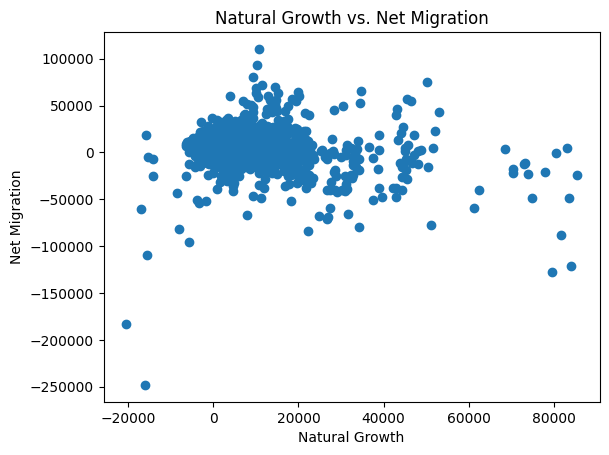

In [ ]:
plt.scatter(growth_df['Natural_Growth'], growth_df['Net_Migration'])
plt.xlabel('Natural Growth')
plt.ylabel('Net Migration')
plt.title('Natural Growth vs. Net Migration')

**Conclusion #4:** The correlation coefficient of 0.01 indicates that there is no linear relationship between natural growth and net migration. The scatterplot also shows no apparent non-linear relationship.